
# Ridge regression

Ridge regression is a modified version of linear regression that adds an L2 penalty (the sum of the squared coefficient values) to the loss function to prevent overfitting and handle multicollinearity

# More information clink on the below link

https://docs.google.com/document/d/1xaW_i5bFC1kadEgZPDGhJQ-KkVBybDpurUS5w7RiMUs/edit?usp=sharing

# Notes and Q and Answer

https://docs.google.com/document/d/1rxRrq4nhCyosMYcPB1Zj1OCxaS15ovrSiE6HgmCfBPA/edit?usp=sharing

# What does Ridge do ?

`Minimize the prediction error, but also penalize very large coefficients.`

`In short - Ridge's main purpose is controling coefficient size`

`One of the most important parameter in ridge regression`

alpha=0.01

`Our project workflow would be :-`

Load libraries
      ↓
Load Diabetes dataset
      ↓
Explore dataset
      ↓
Separate X and y
      ↓
Train/Test Split
      ↓
Scale features
      ↓
Linear Regression baseline
      ↓
Ridge Regression
      ↓
Evaluate
      ↓
Try different alpha values
      ↓
Cross-validation
      ↓
Choose best alpha
      ↓
Final Ridge model
      ↓
Evaluate
      ↓
Compare Linear vs Ridge
      ↓
Save model

# Coding

In [21]:
# NumPy is used for numerical calculations.
import numpy as np

# Pandas is used for DataFrame operations.
import pandas as pd

# Matplotlib is used for visualization.
import matplotlib.pyplot as plt

# Load the built-in Diabetes regression dataset from Scikit-learn.
from sklearn.datasets import load_diabetes

# Splits the dataset into training and testing data.
from sklearn.model_selection import train_test_split

# StandardScaler standardizes the input features.
from sklearn.preprocessing import StandardScaler

# LinearRegression will be our baseline model.
from sklearn.linear_model import LinearRegression

# Ridge is the regularized regression algorithm we are studying.
from sklearn.linear_model import Ridge

# Pipeline allows us to combine preprocessing and the model.
from sklearn.pipeline import Pipeline

# Cross-validation helps us select a good alpha value.
from sklearn.model_selection import cross_val_score

# Regression evaluation metrics.
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load Dataset

In [22]:
# Load the Diabetes regression dataset.
diabetes = load_diabetes(as_frame=True)

# Convert the dataset into a Pandas DataFrame.
df = diabetes.frame

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


# Explore dataset

In [23]:
print("Shape:", df.shape)

# why 11 columns ? because 10 features and 1 columns 

Shape: (442, 11)


# Check column names

In [24]:
# Display all column names.
print(df.columns)

Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'target'],
      dtype='str')


# Check information 


In [25]:
df.info

<bound method DataFrame.info of           age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  target  

In [26]:
# statistical summary 
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [27]:
# checking missing values 

# Count missing values in every column.
print(df.isnull().sum())

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


In [28]:
# separate X and y 

# X contains all input features.
X = df.drop("target", axis=1)

# y contains the continuous value that we want to predict.
y = df["target"]

In [29]:
# Checking 

# X should contain 10 features.
print("X shape:", X.shape)

# y should contain 442 target values.
print("y shape:", y.shape)

X shape: (442, 10)
y shape: (442,)


In [30]:
# Train test split 



# Split the data into:
# 80% training data
# 20% testing data
#
# random_state=42 makes the split reproducible.
X_train,X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Why do we need scaling 
# This is particularly important for ridge .
# Ridge penalizes coefficients: 
 # alpha × sum(coefficient²) 

 # StandardScaler approximately transforms: 
 # x_new = (x - mean) / standard_deviation

 # after scaling, features are generally centered around: 
 # mean  = 0, standard deviation - 1
 

In [31]:
# Create linear regression baseline 
# Create the Linear Regression model.
linear_model = LinearRegression()

In [32]:
# Train 

# Train Linear Regression using the training data.
linear_model.fit(X_train, y_train)

#Predict 
# Predict the target values for unseen test data.
y_pred_linear = linear_model.predict(X_test)


In [33]:
# Evaluation Function 
def evaluate_model(y_true, y_pred):
    # MAE = average absolute prediction error.
    mae = mean_absolute_error(y_true, y_pred)

    # MSE = average squared prediction error.
    mse = mean_squared_error(y_true, y_pred)

    # RMSE = square root of MSE.
    rmse = np.sqrt(mse)

    # R² measures the proportion of target variance explained.
    r2 = r2_score(y_true, y_pred)

    print("MAE :", mae)
    print("MSE :", mse)
    print("RMSE:", rmse)
    print("R²  :", r2)


In [34]:
# Evaluate the baseline Linear Regression model.
print("Linear Regression")
print("-" * 30)

evaluate_model(y_test, y_pred_linear)

Linear Regression
------------------------------
MAE : 42.79409467959994
MSE : 2900.1936284934804
RMSE: 53.85344583676592
R²  : 0.4526027629719196


# Now the ridge regression 
# here is the major difference .


In [35]:
# What do linear regression :-  Minimize prediction error. 
# Ridge : Minimize prediction error + Penalize large coefficients

# Create the model 

# Create a Ridge Regression model.
#
# alpha=1.0 controls the strength of L2 regularization.
ridge_model = Ridge(alpha=1.0) # but we should scale the data first . 
# So instead of manually scaling we will use a Pipeline . 

# Ridge Pipeline 

# Create a pipeline containing:
#
# 1. StandardScaler
#       ↓
#    Standardizes features
#
# 2. Ridge
#       ↓
#    Performs regularized regression
#
ridge_pipeline = Pipeline([
    
    ("scaler", StandardScaler()),
    
    ("ridge", Ridge(alpha=1.0))
])

In [36]:
# Train Ridge 
# Train the complete pipeline.
ridge_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [37]:
# Predict 
# Predict the target values for the test dataset.
y_pred_ridge = ridge_pipeline.predict(X_test)

In [38]:
# Evaluate the Ridge model.
print("Ridge Regression")
print("-" * 30)

evaluate_model(y_test, y_pred_ridge)

Ridge Regression
------------------------------
MAE : 42.81199941834889
MSE : 2892.0145657501735
RMSE: 53.7774540653439
R²  : 0.45414652070698214


In [39]:
# Calculate Linear Regression metrics.
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, y_pred_linear)


# Calculate Ridge Regression metrics.
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_mse = mean_squared_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, y_pred_ridge)

In [40]:
# Create a table to compare both models.
comparison = pd.DataFrame({
    
    "Model": [
        "Linear Regression",
        "Ridge Regression"
    ],
    
    "MAE": [
        linear_mae,
        ridge_mae
    ],
    
    "MSE": [
        linear_mse,
        ridge_mse
    ],
    
    "RMSE": [
        linear_rmse,
        ridge_rmse
    ],
    
    "R2": [
        linear_r2,
        ridge_r2
    ]
})

comparison

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,42.794095,2900.193628,53.853446,0.452603
1,Ridge Regression,42.811999,2892.014566,53.777454,0.454147


# Now the Most importatn part - Finding Good ALpha

In [42]:
# Alpha = strength of regularization 

# We shouldn't assume:
# alpha = 1 
# isautomatically the best . 


# We will test sevarel values 

# Different regularization strengths that we want to test.
alphas = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100,
    1000
]

# Test Different Alpha Values


# Store the results for each alpha.
results = []


# Try each alpha value.
for alpha in alphas:

    # Create a pipeline for the current alpha.
    model = Pipeline([
        
        # Standardize the features.
        ("scaler", StandardScaler()),
        
        # Ridge with the current alpha.
        ("ridge", Ridge(alpha=alpha))
    ])

    # Train the model.
    model.fit(X_train, y_train)

    # Make predictions on the test data.
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics.
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Store the results.
    results.append({
        "Alpha": alpha,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })


# Convert into dataframe 

# Convert the results list into a DataFrame.
results_df = pd.DataFrame(results)

# Display the results.
results_df

,Alpha,MAE,MSE,RMSE,R2
0,0.001,42.794102,2900.181731,53.853335,0.452605
1,0.010,42.794171,2900.075130,53.852346,0.452625
2,0.100,42.796235,2899.054556,53.842869,0.452818
3,1.000,42.811999,2892.014566,53.777454,0.454147
4,10.000,42.856825,2875.778718,53.626288,0.457211
5,100.000,43.250653,2858.224287,53.462363,0.460524
6,1000.000,49.781672,3451.711338,58.751267,0.348507


# Find Best Alpha Using Cross-Validation 

`THis is better than selecting alpha solely from the test set.`

In [44]:
# Store cross-validation results.
cv_results = []


# Test every alpha value.
for alpha in alphas:

    # Create the Ridge pipeline.
    model = Pipeline([
        
        # Standardize features.
        ("scaler", StandardScaler()),
        
        # Ridge with current alpha.
        ("ridge", Ridge(alpha=alpha))
    ])

    # Perform 5-fold cross-validation.
    #
    # The training data is divided into 5 parts.
    # The model trains on 4 and validates on 1.
    # This repeats 5 times.
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    # Store mean and standard deviation.
    cv_results.append({
        "Alpha": alpha,
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

    # Display 

    # Convert the cross-validation results into a DataFrame.
cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Alpha,Mean CV R2,Std CV R2
0,0.001,0.449260,0.144087
1,0.010,0.449292,0.144015
2,0.100,0.449591,0.143328
3,1.000,0.451266,0.138783
4,10.000,0.453937,0.129800
5,100.000,0.451102,0.110196
6,1000.000,0.292711,0.061297


In [ ]:
# Select the best alpha 

# Find the row with the highest average CV R².
best_index = cv_results_df["Mean CV R2"].idxmax()

# Extract the corresponding alpha value.
best_alpha = cv_results_df.loc[
    best_index,
    "Alpha"
]

print("Best Alpha:", best_alpha)

# So instead of saying :- i think alpha is good . 
# I tested several regularization strengths and selected the palpha that performed best during cross-validation.

# That's a much much strongere ML workflow. 

Best Alpha: 10.0


In [50]:

# Create the final Ridge pipeline using the selected alpha.
final_ridge = Pipeline([
    
    # Standardize input features.
    ("scaler", StandardScaler()),
    
    # Ridge with the best alpha.
    ("ridge", Ridge(alpha=best_alpha))
])

In [51]:
# Train 

# Train the final Ridge model.
final_ridge.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [52]:
# Final prediction 

# Predict on the unseen test data.
final_pred = final_ridge.predict(X_test)


In [53]:
# Final Evaluation 

# Evaluate the final Ridge model.
print("Final Ridge Regression")
print("=" * 35)

evaluate_model(y_test, final_pred)

Final Ridge Regression
MAE : 42.856825247800614
MSE : 2875.7787184218437
RMSE: 53.6262875688952
R²  : 0.45721095677808476


In [54]:
# Compare Final Ridge vs regression 

# Create a final comparison table.
final_comparison = pd.DataFrame({
    
    "Model": [
        "Linear Regression",
        "Final Ridge Regression"
    ],
    
    "MAE": [
        linear_mae,
        mean_absolute_error(y_test, final_pred)
    ],
    
    "RMSE": [
        linear_rmse,
        np.sqrt(mean_squared_error(y_test, final_pred))
    ],
    
    "R2": [
        linear_r2,
        r2_score(y_test, final_pred)
    ]
})

final_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,42.794095,53.853446,0.452603
1,Final Ridge Regression,42.856825,53.626288,0.457211


# Look at ridge coefficients

`This is useful because ridge's main purpose is controlling coeffcient size.`


In [55]:
# First get the trained ridge model .

# Extract the trained Ridge model from the pipeline.
ridge_estimator = final_ridge.named_steps["ridge"]

In [56]:
# Get coefficients: 
# Create a table containing each feature and its Ridge coefficient.
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": ridge_estimator.coef_
})

coefficients

,Feature,Coefficient
0,age,1.931332
1,sex,-11.028192
2,bmi,25.605561
3,bp,16.304191
4,s1,-12.934236
5,s2,0.538173
6,s3,-6.125109
7,s4,8.569484
8,s5,22.749308
9,s6,2.918146


# let's compare linear regression coefficients.

In [57]:
# Create a table containing Linear Regression coefficients.
linear_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Linear Coefficient": linear_model.coef_
})

linear_coefficients

,Feature,Linear Coefficient
0,age,37.904021
1,sex,-241.964362
2,bmi,542.428759
3,bp,347.703844
4,s1,-931.488846
5,s2,518.062277
6,s3,163.419983
7,s4,275.317902
8,s5,736.198859
9,s6,48.670657


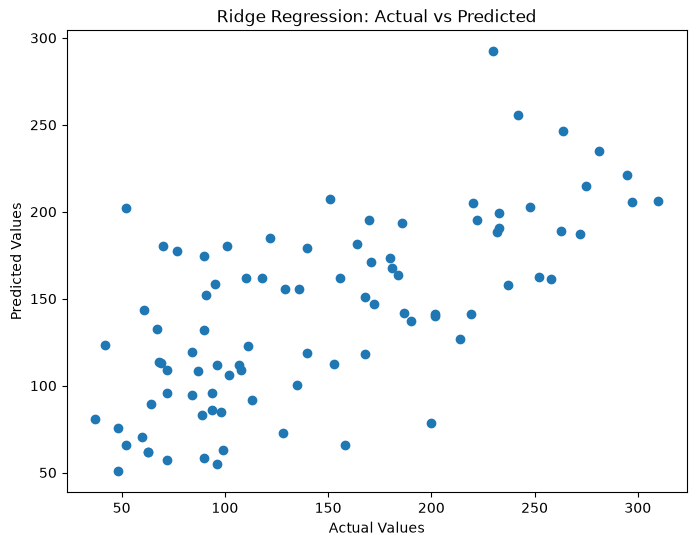

In [58]:
# Plot actual target values against Ridge predictions.
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_pred
)

# Label the axes.
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

# Add title.
plt.title("Ridge Regression: Actual vs Predicted")

# Display the graph.
plt.show()
